In [1]:
import os
import keras
import math
import glob
import random
import pickle
import time
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm
import tensorflow as tf
from keras.layers import *
from keras.optimizers import *
from keras import backend as K
from keras.models import Model
import matplotlib.pyplot as plt
from scipy.signal import medfilt
from collections import defaultdict
from scipy.spatial.distance import cdist
import scipy.ndimage.interpolation as inter
from tensorflow.keras.models import load_model
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.callbacks import TensorBoard
from sklearn.model_selection import KFold, StratifiedKFold
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve
)
from sklearn.preprocessing import label_binarize

2025-04-24 23:50:33.009978: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-04-24 23:50:33.022939: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745556633.036901  620610 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745556633.040616  620610 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-04-24 23:50:33.054325: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
random.seed(1234)

class Config():
    def __init__(self):
        self.frame_l = 72 # the length of frames
        self.joint_n = 33 # the number of joints
        self.joint_d = 3 # the dimension of joints
        self.clc = 3 # the number of coarse class
        self.feat_d = 528
        self.filters = 64
        self.num_folds = 5
        self.data_dir = r"/home/nyam/Ms_Thesis/Autism/Project_v3/Stimming/DataProcessing/v2/skel_clean_aug_3"
        self.dataset_info = r"/home/nyam/Ms_Thesis/Autism/Project_v3/Stimming/DataProcessing/v2/dataset_info_clean_aug_3.txt"
C = Config()

In [3]:
#Rescale to be 64 frames
def zoom(p,target_l=72,joints_num=33,joints_dim=3):
    l = p.shape[0]
    p_new = np.empty([target_l,joints_num,joints_dim])
    for m in range(joints_num):
        for n in range(joints_dim):
            p[:,m,n] = medfilt(p[:,m,n],3)
            p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
    return p_new


def get_CG(p,C):
    M = []
    iu = np.triu_indices(C.joint_n,1,C.joint_n)
    for f in range(C.frame_l):
        #distance max
        d_m = cdist(p[f],np.concatenate([p[f],np.zeros([1,C.joint_d])]),'euclidean')
        d_m = d_m[iu]
        M.append(d_m)
    M = np.stack(M)
    return M

def normlize_range(p):
    # normolize to start point, use the center for hand case
    p[:,:,0] = p[:,:,0]-np.mean(p[:,:,0])
    p[:,:,1] = p[:,:,1]-np.mean(p[:,:,1])
    p[:,:,2] = p[:,:,2]-np.mean(p[:,:,2])
    return p

# Function to read dataset info from file
def read_dataset_info(file_path):
    dataset_info = []
    with open(file_path, "r") as info_file:
        for line in info_file:
            # Strip any leading or trailing whitespace and split the line by tabs
            info = line.strip().split("\t")
            if info[1] != "HandAction":
                dataset_info.append(info)
    return dataset_info

# Function to perform label encoding
def label_encode(dataset_info):
    label_encoder = LabelEncoder()
    labels = [info[1] for info in dataset_info]
    #print(dataset_info)
    encoded_labels = label_encoder.fit_transform(labels)

    for i, info in enumerate(dataset_info):
        dataset_info[i] = list(info)  # Convert tuple to list
        dataset_info[i][1] = encoded_labels[i]  # Modify the label
    
    return dataset_info


In [4]:
def poses_diff(x):
    H, W = x.get_shape()[1], x.get_shape()[2]
    x = tf.subtract(x[:, 1:, ...], x[:, :-1, ...])
    x = tf.image.resize(x, size=[H, W])
    return x

def pose_motion(P, frame_l):
    P_diff_slow = Lambda(lambda x: poses_diff(x))(P)
    P_diff_slow = Reshape((frame_l, -1))(P_diff_slow)
    
    P_fast = Lambda(lambda x: x[:, ::2, ...])(P)
    P_diff_fast = Lambda(lambda x: poses_diff(x))(P_fast)
    P_diff_fast = Reshape((int(frame_l / 2), -1))(P_diff_fast)
    return P_diff_slow, P_diff_fast

def c1D(x, filters, kernel):
    x = Conv1D(filters, kernel_size=kernel, padding='same', use_bias=False)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(alpha=0.2)(x)
    return x

def block(x, filters):
    x = c1D(x, filters, 3)
    x = c1D(x, filters, 3)
    return x

def d1D(x,filters):
    x = Dense(filters,use_bias=False)(x)
    x = BatchNormalization()(x)
    x = LeakyReLU(alpha=0.2)(x)
    return x

def build_FM(frame_l, joint_n, joint_d, feat_d, filters):
    M = Input(shape=(frame_l, feat_d))
    P = Input(shape=(frame_l, joint_n, joint_d))

    diff_slow, diff_fast = pose_motion(P, frame_l)

    x = c1D(M, filters * 2, 1)
    x = SpatialDropout1D(0.1)(x)
    x = c1D(x, filters, 3)
    x = SpatialDropout1D(0.1)(x)
    x = c1D(x, filters, 1)
    x = MaxPooling1D(2)(x)
    x = SpatialDropout1D(0.1)(x)

    x_d_slow = c1D(diff_slow, filters * 2, 1)
    x_d_slow = SpatialDropout1D(0.1)(x_d_slow)
    x_d_slow = c1D(x_d_slow, filters, 3)
    x_d_slow = SpatialDropout1D(0.1)(x_d_slow)
    x_d_slow = c1D(x_d_slow, filters, 1)
    x_d_slow = MaxPooling1D(2)(x_d_slow)
    x_d_slow = SpatialDropout1D(0.1)(x_d_slow)

    x_d_fast = c1D(diff_fast, filters * 2, 1)
    x_d_fast = SpatialDropout1D(0.1)(x_d_fast)
    x_d_fast = c1D(x_d_fast, filters, 3)
    x_d_fast = SpatialDropout1D(0.1)(x_d_fast)
    x_d_fast = c1D(x_d_fast, filters, 1)
    x_d_fast = SpatialDropout1D(0.1)(x_d_fast)

    x = Concatenate()([x, x_d_slow, x_d_fast])
    
    x = block(x, filters)
    x = MaxPooling1D(2)(x)
    x = SpatialDropout1D(0.1)(x)

    x = block(x, filters * 2)
    x = MaxPooling1D(2)(x)
    x = SpatialDropout1D(0.1)(x)

    x = block(x, filters * 4)
    x = MaxPooling1D(2)(x)
    x = SpatialDropout1D(0.1)(x)
    
    return Model(inputs=[M, P], outputs=x)

def build_localized_model():
    # Original full skeleton model
    spinning_model = build_FM(frame_l=C.frame_l, joint_n=33, joint_d=3, feat_d=528, filters=64)

    # Head points model (assuming head points correspond to first 12 joints)
    head_model = build_FM(frame_l=C.frame_l, joint_n=11, joint_d=3, feat_d=528, filters=64)

    # Arm points model (assuming arm points correspond to next 12 joints)
    arms_model = build_FM(frame_l=C.frame_l, joint_n=11, joint_d=3, feat_d=528, filters=64)

    fingers_model = build_FM(frame_l=C.frame_l, joint_n=8, joint_d=3, feat_d=528, filters=64)


    # Inputs for each model
    M_input = Input(shape=(C.frame_l, 528))           # Feature input for all models
    P_full_input = Input(shape=(C.frame_l, 33, 3))    # Pose input for full model
    P_head_input = P_full_input[:, :, :11, :]  # Slicing for head points (joints [0:11])
    P_arms_input = P_full_input[:, :, 11:22, :]  # Slicing for arm points (joints [11:23])
    #P_fingers_input = P_full_input[:, :, 15:23, :]  # Slicing for finger points (joints [15:22])

    # Outputs from each sub-model
    spinning_output = spinning_model([M_input, P_full_input])
    head_output = head_model([M_input, P_head_input])
    arms_output = arms_model([M_input, P_arms_input])
    #fingers_output = fingers_model([M_input, P_fingers_input])
    

    # Concatenate the outputs
    concatenated_output = Concatenate()([spinning_output,head_output, arms_output])

    x = GlobalMaxPool1D()(concatenated_output)

    x = d1D(x,512)
    x = Dropout(0.5)(x)
    x = d1D(x,254)
    x = Dropout(0.5)(x)
    x = d1D(x,128)
    x = Dropout(0.5)(x)
    x = d1D(x,64)
    x = Dropout(0.5)(x)
    x = d1D(x,32)
    x = Dropout(0.5)(x)
    x = Dense(C.clc, activation='softmax')(x)
    
    x = Model(inputs=[M_input, P_full_input], outputs=x)
    return x

# Create and compile the final model
localized_model = build_localized_model()
localized_model.summary()


I0000 00:00:1745556635.427979  620610 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3620 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 72, 33, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_8       │ (None, 72, 528)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 72, 11, 3) │          0 │ input_layer_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 72, 11, 3) │          0 │ input_layer_9[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional          │ (None, 4, 256)    │    603,392 │ input_layer_8[0]… │
│ (Functional)        │                   │            │ input_layer_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_1        │ (None, 4, 256)    │    586,496 │ input_layer_8[0]… │
│ (Functional)        │                   │            │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ functional_2        │ (None, 4, 256)    │    586,496 │ input_layer_8[0]… │
│ (Functional)        │                   │            │ get_item_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 4, 768)    │          0 │ functional[0][0], │
│ (Concatenate)       │                   │            │ functional_1[0][… │
│                     │                   │            │ functional_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 768)       │          0 │ concatenate_4[0]… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 512)       │    393,216 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_60      │ (None, 512)       │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ leaky_re_lu_60[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 254)       │    130,048 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 254)       │      1,016 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_61      │ (None, 254)       │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 254)       │          0 │ leaky_re_lu_61[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     32,512 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 2,346,459 (8.95 MB)

 Trainable params: 2,334,495 (8.91 MB)

 Non-trainable params: 11,964 (46.73 KB)

In [5]:
# --- Visualization: Confusion Matrix ---
def plot_confusion_matrix(y_true, y_pred, labels):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [6]:
def data_loader(dataset):
    data = {}
    data['pose'] = []
    data['label'] = []
    
    for i in tqdm(range(len(dataset))):
        label = dataset[i][1]
        skeletons = dataset[i][0]
        
        skeleton_path =os.path.join(C.data_dir, str(skeletons))
        
        try:
            p = np.load(skeleton_path).astype('float32')
            for j in range(p.shape[1]):
                p[:, j] = medfilt(p[:, j])
            
            data['pose'].append(p)
            data['label'].append(label)
        except Exception as e:
            print(f"An error occurred while processing {skeletons}: {e}")
            
    X_0 = []
    X_1 = []
    Y = []
    
    for i in tqdm(range(len(data['pose']))):
        p = np.copy(data['pose'][i]).reshape([-1,33,3])
        if(p.shape[0]>10):
            p = zoom(p,target_l=C.frame_l,joints_num=C.joint_n,joints_dim=C.joint_d)
            p = normlize_range(p)
            # print(p)
            label = np.zeros(C.clc)
            #print(int(Train['label'][i]))
            label[int(data['label'][i])] = 1
    
            M = get_CG(p,C)
    
            X_0.append(M)
            X_1.append(p)
            Y.append(label)
    
    return np.stack(X_0) , np.stack(X_1), np.stack(Y)

In [7]:

# Define the path to the dataset info file
output_info_file = C.dataset_info   # Path to dataset info

# Load dataset info
dataset_info = read_dataset_info(output_info_file)

# Group subjects per class
classwise_subjects = defaultdict(lambda: defaultdict(list))

for info in dataset_info:
    class_label = info[1]  # Class (e.g., "Spinning", "HeadBanging")
    filename = info[2]     # Extract filename
    parts = filename.split('_')
    subject_id = f"{parts[1]}_{parts[2]}"  # Unique subject identifier
    
    classwise_subjects[class_label][subject_id].append((filename, class_label))  # Store filename & label


subject_to_label = {}

# Iterate over classwise_subjects to populate subject labels
for class_label, subjects in classwise_subjects.items():
    for subject_id in subjects.keys():
        subject_to_label[subject_id] = class_label  # Assign class label to subject

# Collect unique subjects across all classes
all_subjects = list(subject_to_label.keys())  # Unique subjects
labels = [subject_to_label[subj] for subj in all_subjects]  # List of class labels

# Perform balanced train-test split for each class
random.seed(42)  # Ensure reproducibility
random.shuffle(all_subjects)

# Create subject-level KFold splits
kfold = StratifiedKFold(n_splits=C.num_folds, shuffle=False)  # No shuffle since manually shuffled

fold_results = []
y_true_pred = []
fold_histories = []

for fold, (train_subj_idx, test_subj_idx) in enumerate(kfold.split(all_subjects, labels)):
    print(f"\n--- Fold {fold+1}/{C.num_folds} ---")

    train_subjects = set([all_subjects[i] for i in train_subj_idx])
    test_subjects = set([all_subjects[i] for i in test_subj_idx])

    # Create train and test sets ensuring mutual exclusivity
    train_list = label_encode([vid for class_subjects in classwise_subjects.values() 
                  for subj, vids in class_subjects.items() if subj in train_subjects for vid in vids])
    test_list = label_encode([vid for class_subjects in classwise_subjects.values() 
                 for subj, vids in class_subjects.items() if subj in test_subjects for vid in vids])
    # print(train_subjects)
    # print("------------------------------------")
    # print(test_subjects)
    
    x_0,x_1,y = data_loader(train_list)
    xt_0, xt_1,yt = data_loader(test_list)
    
    localized_stim_net = build_localized_model()
    lr = 1e-3
    localized_stim_net.compile(loss="categorical_crossentropy",optimizer=keras.optimizers.Adam(lr),metrics=['accuracy'])
    lrScheduler = keras.callbacks.ReduceLROnPlateau(monitor='loss', factor=0.1, patience=5, cooldown=2, min_lr=1e-3)

    checkpoint_callback = ModelCheckpoint(
        filepath=f'localized_best_model_fold_{fold+1}.keras',  # Save per fold
        monitor='val_accuracy',  # Track validation accuracy
        save_best_only=True,  # Save only the best model
        mode='max',  # Higher accuracy is better
        verbose=1
    )
    
    history = localized_stim_net.fit([x_0,x_1],y,
            batch_size=8,
            epochs=,
            verbose=True,
            shuffle=True,
            callbacks=[lrScheduler, checkpoint_callback],
            validation_data=([xt_0, xt_1],yt)
            )

    fold_histories.append(history.history)
    
     # Load the best model before evaluating
    localized_stim_net.load_weights(f'localized_best_model_fold_{fold+1}.keras')
    
    Y_pred = localized_stim_net.predict([xt_0, xt_1])
    labels = ['Arm Flapping', 'HeadBanging', 'Spinning']
    
    y_true = []
    for i in np.argmax(yt,axis=1):
        y_true.append(labels[i])
    
    y_pred = []
    for i in np.argmax(Y_pred,axis=1):
        y_pred.append(labels[i])
        
    #plot_confusion_matrix(y_true, y_pred, labels)
    y_true_pred.append([y_true, y_pred, labels])
    
    accuracy = accuracy_score(y_true,y_pred)
    print("Accuracy:", accuracy)

    fold_results.append(accuracy)

# Print final results
avg_accuracy = np.mean(fold_results)
print(f"\nFinal Cross-Validation Accuracy: {avg_accuracy:.4f}")

print(fold_results)



--- Fold 1/5 ---


  0%|                                                                                           | 0/219 [00:00<?, ?it/s]/tmp/ipykernel_620610/3012556727.py:8: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
100%|██████████████████████████████████████████████████████████████████████████████████| 57/57 [00:00<00:00, 167.76it/s]
/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Epoch 1/256


/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/models/functional.py:225: UserWarning: The structure of `inputs` doesn't match the expected structure: ['keras_tensor_638', 'keras_tensor_639']. Received: the structure of inputs=('*', '*')
  warnings.warn(
I0000 00:00:1745556662.267042  620774 service.cc:148] XLA service 0x7fe460016900 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1745556662.267083  620774 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 6GB Laptop GPU, Compute Capability 8.6
2025-04-24 23:51:02.654880: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1745556664.281635  620774 cuda_dnn.cc:529] Loaded cuDNN version 90501
2025-04-24 23:51:09.908952: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng54{k2=8,k12=-1,k13=1,k14=3,k15=0,k17=64,k1

27/28 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3376 - loss: 1.7408

2025-04-24 23:51:42.019220: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng28{k2=1,k3=0} for conv (f32[1,128,1,18]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,64,1,18]{3,2,1,0}, f32[128,64,1,3]{3,2,1,0}), window={size=1x3 pad=0_0x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2025-04-24 23:51:42.836545: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 1.817376989s
Trying algorithm eng28{k2=1,k3=0} for conv (f32[1,128,1,18]{3,2,1,0}, u8[0]{0}) custom-call(f32[1,64,1,18]{3,2,1,0}, f32[128,64,1,3]{3,2,1,0}), window={size=1x3 pad=0_0x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"cudnn_conv_backend_config":{"activatio

... (27 outputs left out)

  0%|                                                                                           | 0/222 [00:00<?, ?it/s]/tmp/ipykernel_620610/3012556727.py:8: DeprecationWarning: Please import `zoom` from the `scipy.ndimage` namespace; the `scipy.ndimage.interpolation` namespace is deprecated and will be removed in SciPy 2.0.0.
  p_new[:,m,n] = inter.zoom(p[:,m,n],target_l/l)[:target_l]
100%|██████████████████████████████████████████████████████████████████████████████████| 54/54 [00:00<00:00, 171.76it/s]
/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Epoch 1/256


/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/models/functional.py:225: UserWarning: The structure of `inputs` doesn't match the expected structure: ['keras_tensor_1974', 'keras_tensor_1975']. Received: the structure of inputs=('*', '*')
  warnings.warn(


28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 851ms/step - accuracy: 0.3437 - loss: 1.6403
Epoch 1: val_accuracy improved from -inf to 0.35185, saving model to localized_best_model_fold_5.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 74s 1s/step - accuracy: 0.3417 - loss: 1.6425 - val_accuracy: 0.3519 - val_loss: 1.1086 - learning_rate: 0.0010
Epoch 2/256
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.4321 - loss: 1.4290
Epoch 2: val_accuracy improved from 0.35185 to 0.37037, saving model to localized_best_model_fold_5.keras
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.4304 - loss: 1.4282 - val_accuracy: 0.3704 - val_loss: 1.1095 - learning_rate: 0.0010
Epoch 3/256
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3524 - loss: 1.3114
Epoch 3: val_accuracy did not improve from 0.37037
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3510 - loss: 1.3154 - val_accuracy: 0.3704 - val_loss: 1.1697 - learning_rate: 0.0010
Epoch 4/256
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.3619 - l


--- Fold 1 Evaluation ---
Accuracy: 0.8772
Weighted Accuracy: 0.8772
Precision: 0.8889
Recall: 0.8889
Weighted F1-score: 0.8772
AUC: 0.9160
IoC: 0.1228

--- Fold 2 Evaluation ---
Accuracy: 0.8596
Weighted Accuracy: 0.8596
Precision: 0.8576
Recall: 0.8603
Weighted F1-score: 0.8606
AUC: 0.8958
IoC: 0.1404

--- Fold 3 Evaluation ---
Accuracy: 0.7963
Weighted Accuracy: 0.7963
Precision: 0.7873
Recall: 0.7884
Weighted F1-score: 0.7981
AUC: 0.8445
IoC: 0.2037

--- Fold 4 Evaluation ---
Accuracy: 0.9231
Weighted Accuracy: 0.9231
Precision: 0.9217
Recall: 0.9175
Weighted F1-score: 0.9226
AUC: 0.9403
IoC: 0.0769

--- Fold 5 Evaluation ---
Accuracy: 0.8148
Weighted Accuracy: 0.8148
Precision: 0.8079
Recall: 0.8042
Weighted F1-score: 0.8151
AUC: 0.8568
IoC: 0.1852


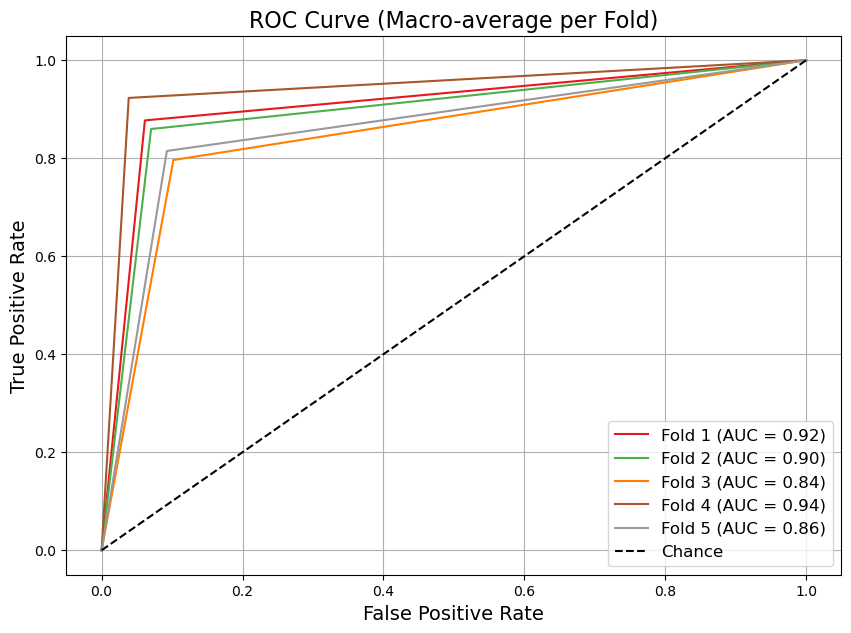


--- Final Cross-Validation Results ---
Accuracy: Mean = 0.8542, Std = 0.0452
Weighted Accuracy: 0.8542
Precision: 0.8527
Recall: 0.8519
Weighted F1-score: 0.8547
AUC: 0.8907
IoC: 0.1458


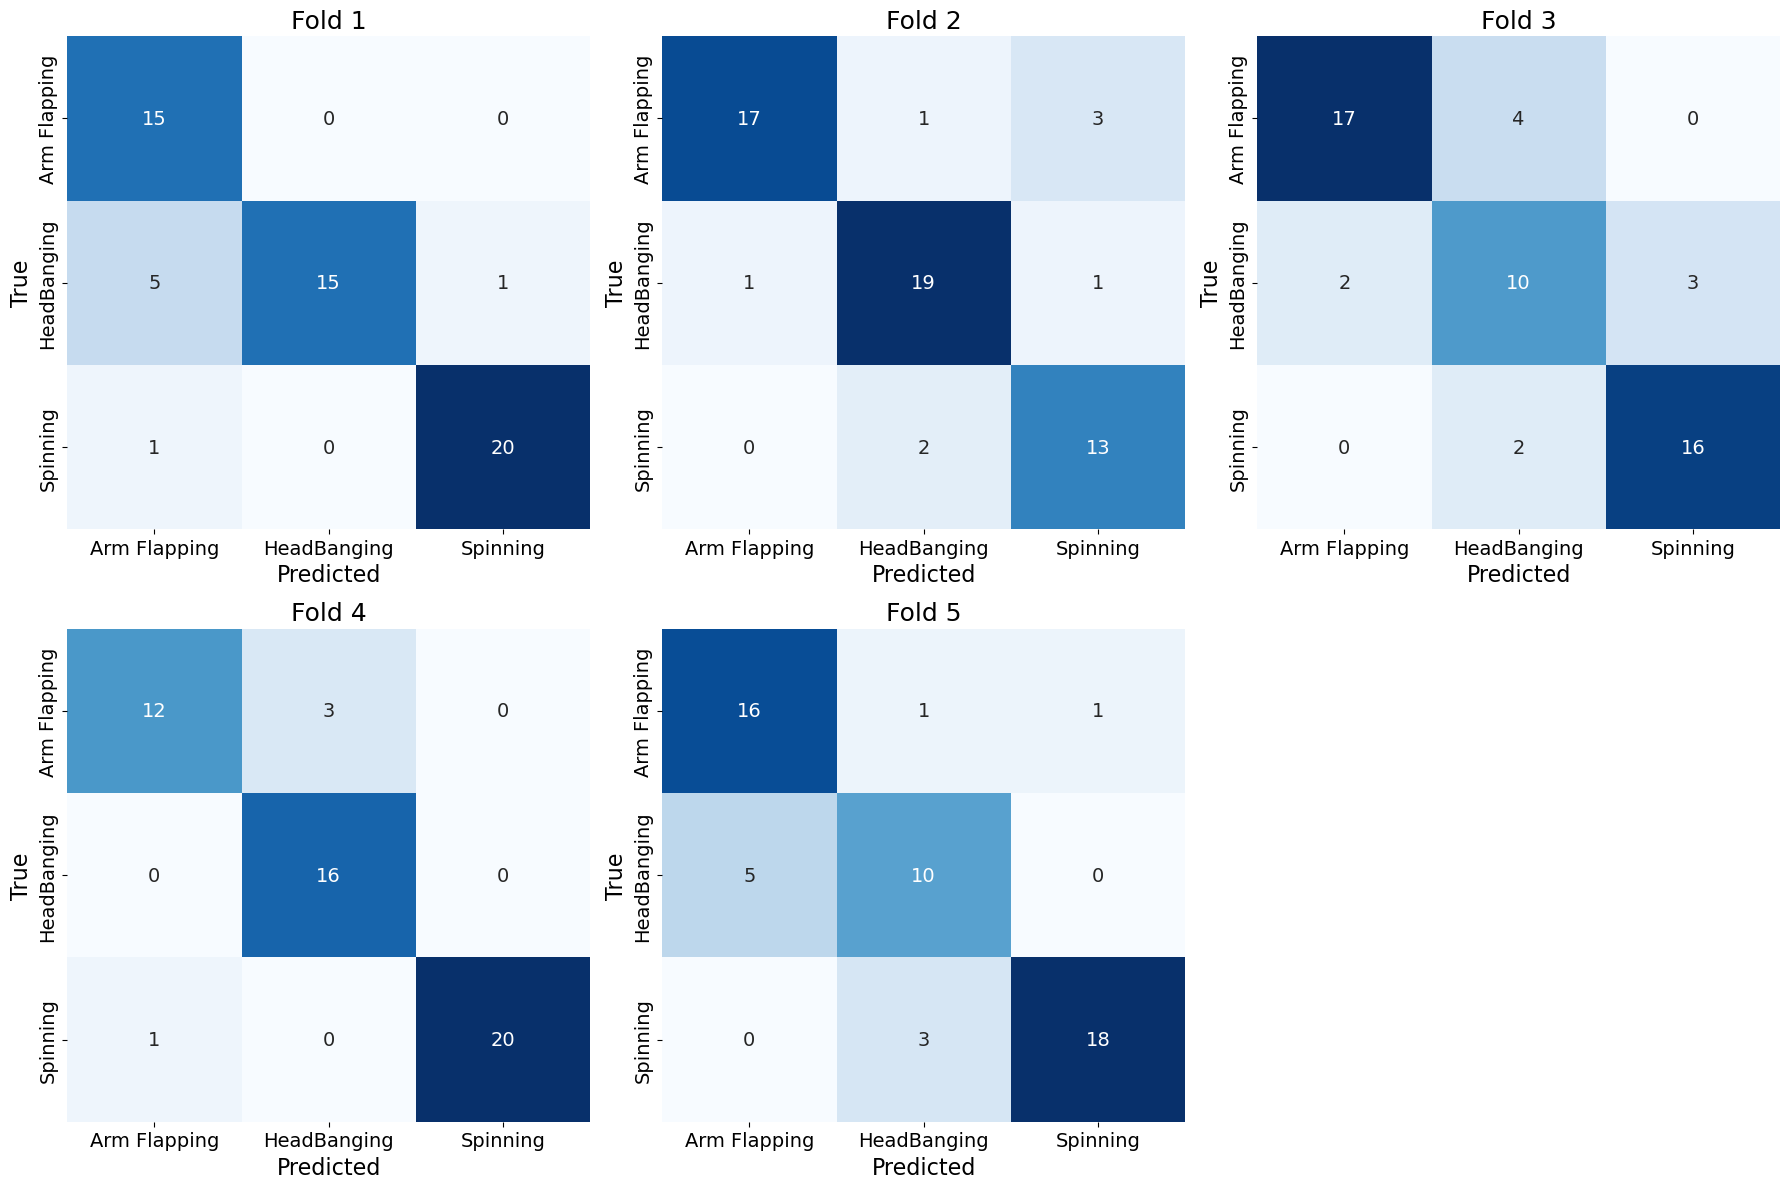

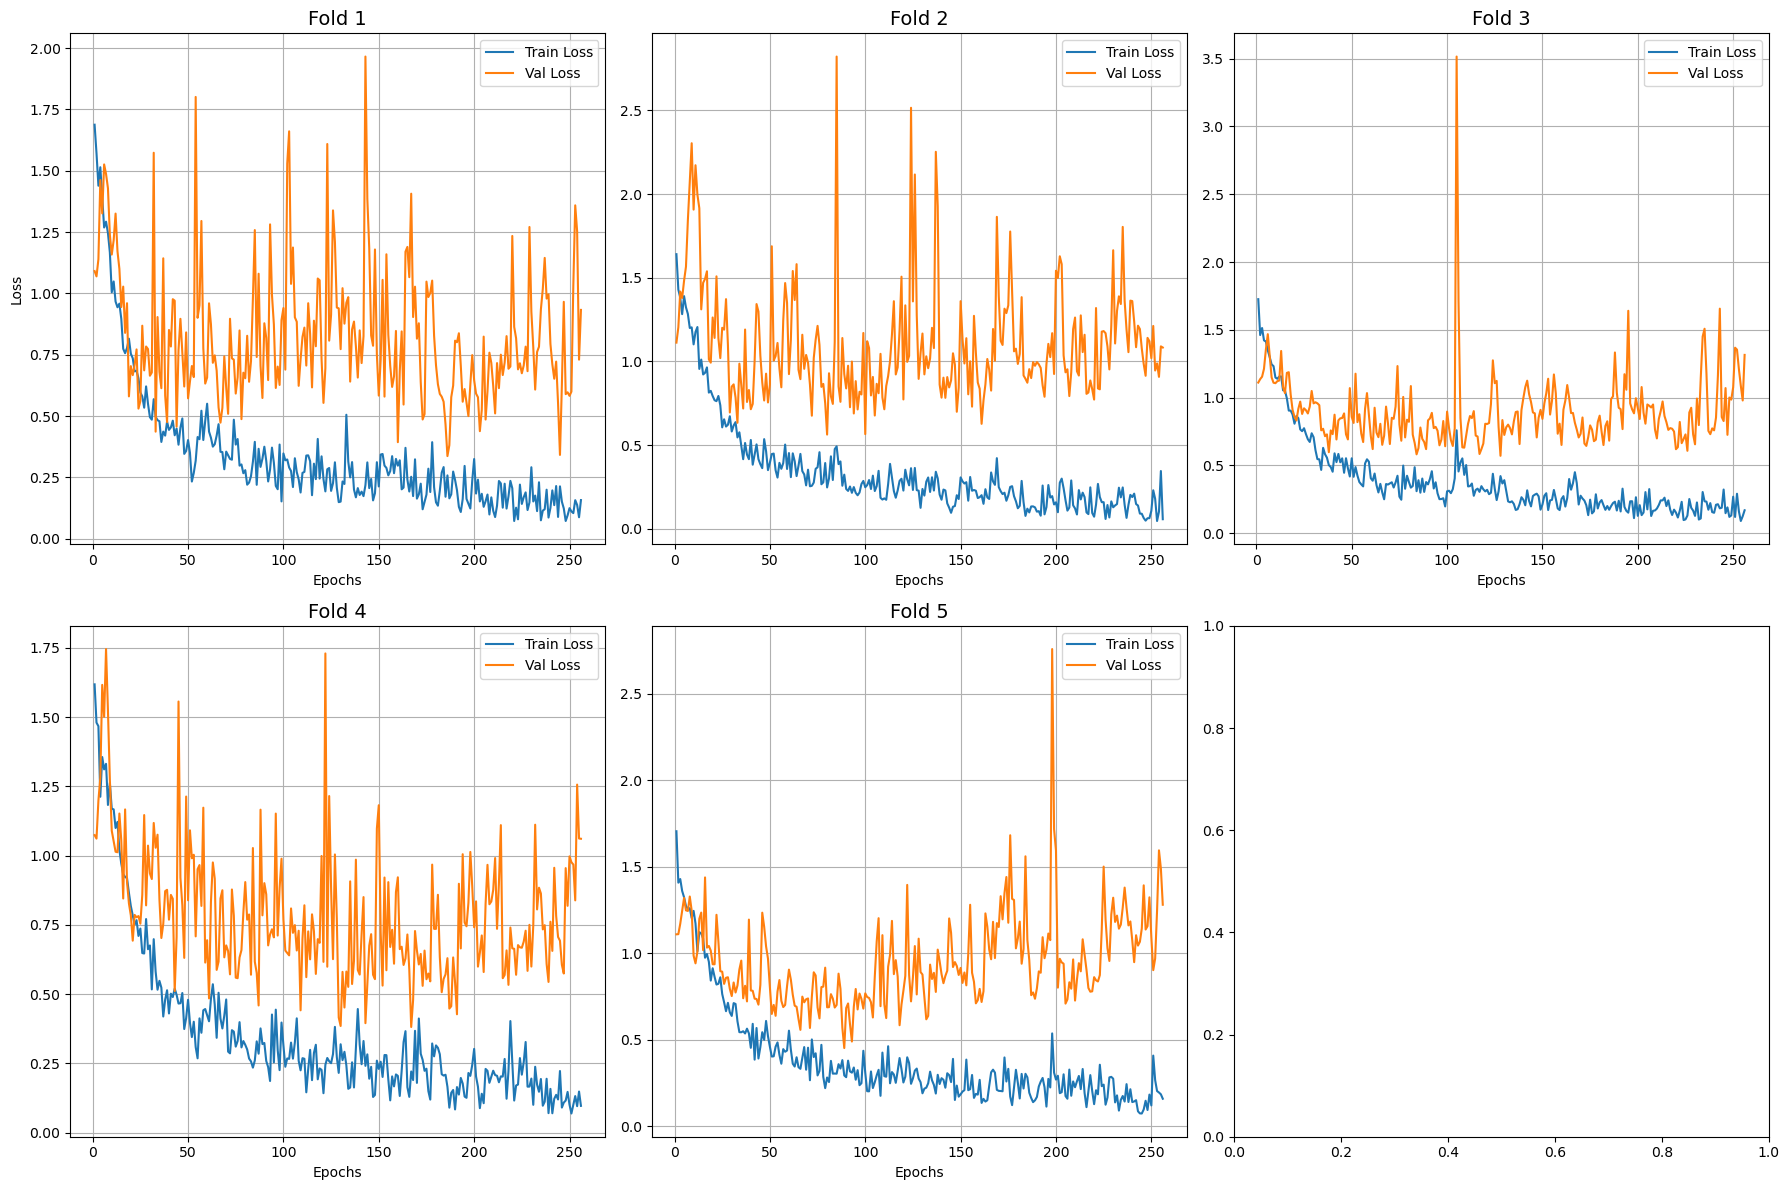

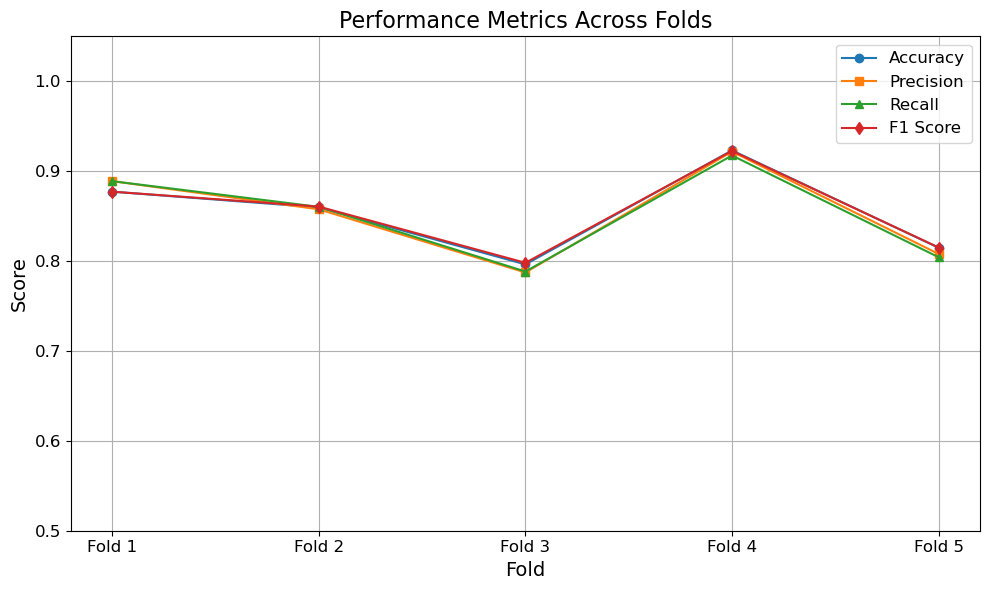

In [8]:
# Initialize
conf_matrices = []
accuracies = []
weighted_accuracies = []
precisions = []
recalls = []
weighted_f1_scores = []
auc_scores = []
ioc_scores = []

num_classes = len(y_true_pred[0][2])  # from labels
all_labels = y_true_pred[0][2]        # consistent labels

# Color palette for ROC
colors = plt.cm.Set1(np.linspace(0, 1, len(y_true_pred)))

# For ROC plotting
plt.figure(figsize=(10, 7))
for fold, data in enumerate(y_true_pred):
    y_true, y_pred, labels = data

    print(f"\n--- Fold {fold+1} Evaluation ---")

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    conf_matrices.append(cm)

    # Accuracy
    acc = accuracy_score(y_true, y_pred)
    weighted_acc = np.sum(np.diag(cm)) / np.sum(cm)
    accuracies.append(acc)
    weighted_accuracies.append(weighted_acc)

    # Precision, recall, F1
    precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    weighted_f1 = f1_score(y_true, y_pred, average='weighted')

    precisions.append(precision)
    recalls.append(recall)
    weighted_f1_scores.append(weighted_f1)

    # AUC (Macro)
    try:
        y_true_bin = label_binarize(y_true, classes=labels)
        y_pred_bin = label_binarize(y_pred, classes=labels)
        auc = roc_auc_score(y_true_bin, y_pred_bin, average='macro', multi_class="ovr")
        auc_scores.append(auc)

        # Macro-average ROC (manual, since you want visualization)
        fpr, tpr, _ = roc_curve(y_true_bin.ravel(), y_pred_bin.ravel())
        plt.plot(fpr, tpr, label=f'Fold {fold+1} (AUC = {auc:.2f})', color=colors[fold])
    except ValueError:
        auc_scores.append(np.nan)

    # IoC
    ioc = 1 - acc
    ioc_scores.append(ioc)

    # Fold scores
    print(f"Accuracy: {acc:.4f}")
    print(f"Weighted Accuracy: {weighted_acc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"Weighted F1-score: {weighted_f1:.4f}")
    print(f"AUC: {auc:.4f}")
    print(f"IoC: {ioc:.4f}")

# ===== Plot 2: ROC Curve Summary =====
plt.plot([0, 1], [0, 1], 'k--', label='Chance')
plt.xlabel('False Positive Rate', fontsize=14)
plt.ylabel('True Positive Rate', fontsize=14)
plt.title('ROC Curve (Macro-average per Fold)', fontsize=16)
plt.legend(fontsize=12)
plt.grid(True)
plt.show()

# ===== Final Results =====
print("\n--- Final Cross-Validation Results ---")
print(f"Accuracy: Mean = {np.mean(accuracies):.4f}, Std = {np.std(accuracies):.4f}")
print(f"Weighted Accuracy: {np.mean(weighted_accuracies):.4f}")
print(f"Precision: {np.mean(precisions):.4f}")
print(f"Recall: {np.mean(recalls):.4f}")
print(f"Weighted F1-score: {np.mean(weighted_f1_scores):.4f}")
print(f"AUC: {np.nanmean(auc_scores):.4f}")
print(f"IoC: {np.mean(ioc_scores):.4f}")

# ===== Plot 1: Confusion Matrices =====
fig, axs = plt.subplots(2, 3, figsize=(18, 12))
axs = axs.flatten()

for i, cm in enumerate(conf_matrices):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=all_labels, yticklabels=all_labels,
                ax=axs[i], cbar=False, annot_kws={"size": 14})
    axs[i].set_title(f'Fold {i+1}', fontsize=18)
    axs[i].set_xlabel('Predicted', fontsize=16)
    axs[i].set_ylabel('True', fontsize=16)
    axs[i].tick_params(axis='both', labelsize=14)

if len(conf_matrices) < 6:
    fig.delaxes(axs[-1])

plt.tight_layout()
plt.show()

# Create 5 subplots loss functions (2 row, 3 columns)
fig, axs = plt.subplots(2,3, figsize=(18, 12))
axs = axs.flatten()
for i, hist in enumerate(fold_histories):
    epochs = range(1, len(hist['loss']) + 1)
    axs[i].plot(epochs, hist['loss'], label='Train Loss')
    axs[i].plot(epochs, hist['val_loss'], label='Val Loss')
    axs[i].set_title(f'Fold {i+1}', fontsize=14)
    axs[i].set_xlabel('Epochs')
    if i == 0:
        axs[i].set_ylabel('Loss')
    axs[i].grid(True)
    axs[i].legend()

plt.tight_layout()
plt.show()


# ===== Plot 3: Accuracy, Precision, Recall, F1 =====
folds = [f'Fold {i+1}' for i in range(len(y_true_pred))]

plt.figure(figsize=(10, 6))
plt.plot(folds, accuracies, marker='o', label='Accuracy')
plt.plot(folds, precisions, marker='s', label='Precision')
plt.plot(folds, recalls, marker='^', label='Recall')
plt.plot(folds, weighted_f1_scores, marker='d', label='F1 Score')

plt.title('Performance Metrics Across Folds', fontsize=16)
plt.xlabel('Fold', fontsize=14)
plt.ylabel('Score', fontsize=14)
plt.ylim(0.5, 1.05)
plt.grid(True)
plt.legend(fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


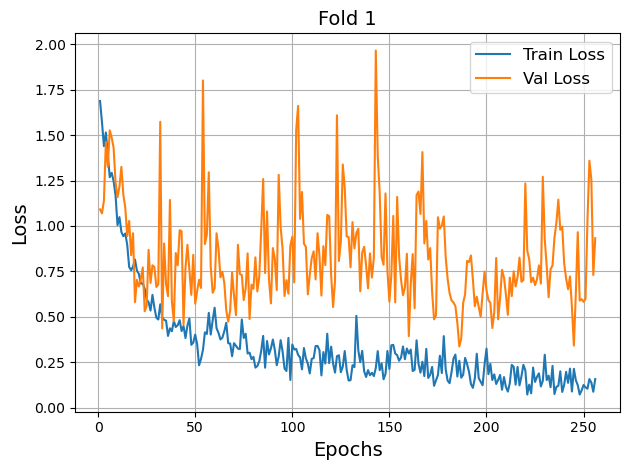

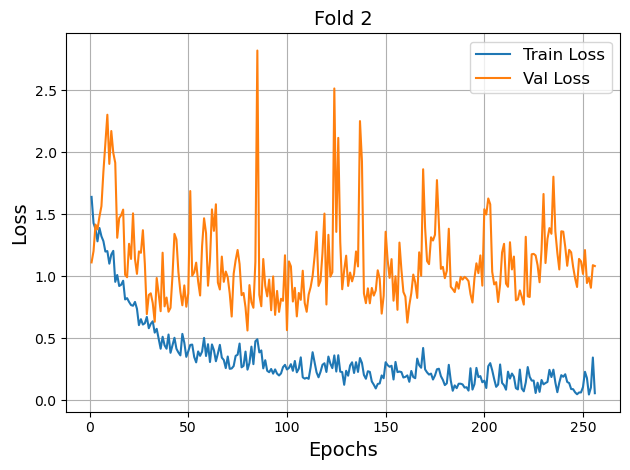

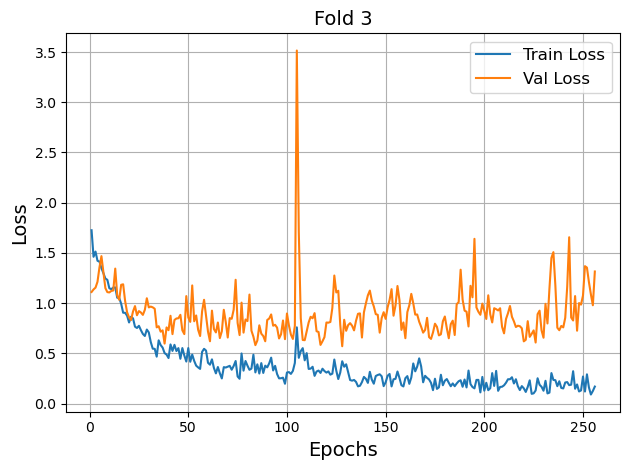

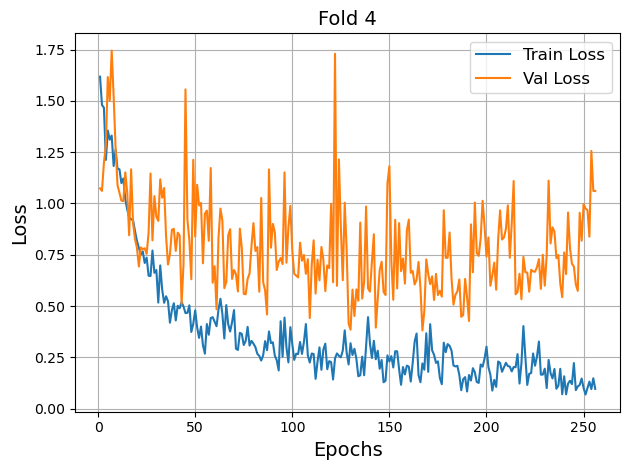

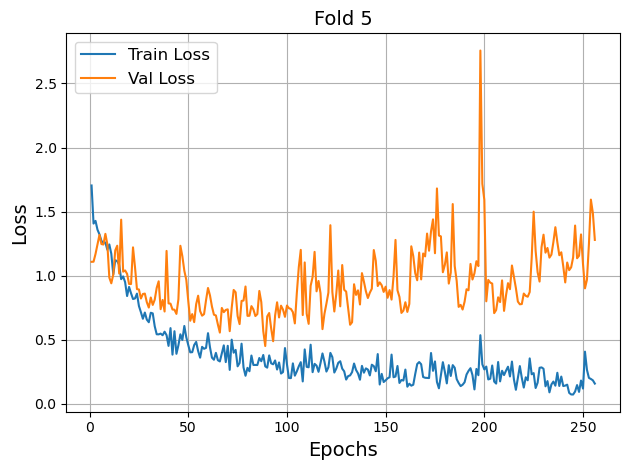

In [9]:
for i, hist in enumerate(fold_histories):
    epochs = range(1, len(hist['loss']) + 1)
    
    plt.plot(epochs, hist['loss'], label='Train Loss')
    plt.plot(epochs, hist['val_loss'], label='Val Loss')
    plt.title(f'Fold {i+1}', fontsize=14)
    if i == 0:
        axs[i].set_ylabel('Loss')
    axs[i].grid(True)
    axs[i].legend()
    
    plt.xlabel('Epochs', fontsize=14)
    plt.ylabel('Loss', fontsize=14)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [10]:
# Define models and their input shapes
model_dict = {
    "Local_StimNet": {
        "model": localized_model,
        "input_shapes": [(1, 72, 528), (1, 72, 33, 3)]
    }
}

def measure_inference_time(model, input_shapes, runs=100):
    motion_input = np.random.randn(*input_shapes[0]).astype(np.float32)
    pose_input = np.random.randn(*input_shapes[1]).astype(np.float32)
    inputs = [motion_input, pose_input]

    # Warm-up
    model.predict(inputs)

    # Timed runs
    start = time.time()
    for _ in range(runs):
        model.predict(inputs)
    end = time.time()

    return ((end - start) / runs) * 1000  # ms

def get_model_stats(model, save_path="temp_model.keras"):
    model.save(save_path, include_optimizer=False)
    size_mb = os.path.getsize(save_path) / (1024 * 1024)
    os.remove(save_path)
    param_count = model.count_params()
    return param_count, round(size_mb, 2)

# Collect results
results = []

for model_name, info in model_dict.items():
    try:
        model = info["model"]
        input_shapes = info["input_shapes"]

        inf_time = measure_inference_time(model, input_shapes)
        params, size_mb = get_model_stats(model)

        results.append({
            "Model": model_name,
            "Parameters": params,
            "Model Size (MB)": size_mb,
            "Inference Time (ms)": round(inf_time, 2)
        })

    except Exception as e:
        results.append({
            "Model": model_name,
            "Parameters": "Error",
            "Model Size (MB)": "Error",
            "Inference Time (ms)": f"Failed: {str(e)}"
        })


# Output results
df = pd.DataFrame(results)
df.to_csv("model_timing_report.csv", index=False)
print(df)

/home/nyam/anaconda3/lib/python3.12/site-packages/keras/src/models/functional.py:225: UserWarning: The structure of `inputs` doesn't match the expected structure: ['keras_tensor_304', 'keras_tensor_305']. Received: the structure of inputs=('*', '*')
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━